# Which outlet temperature? Three treatments of the outflow enthalpy against the full simulation

**The question.** In the full simulation the gas that leaves through the outlet reed carries the instantaneous CV temperature $T(t)$, which swings adiabatically with the pressure over each cycle. The averaged model replaces it by a single number. Three choices are compared here, all in the *averaged model only* — the full simulation is unchanged and is the reference:

1. **$\bar T$** (current, sections 5 and 7): the outflow carries the cycle-mean CV temperature.
2. **$T_{out} = \bar T (P^*/\bar P)^{\varepsilon}$**: the CV gas at the pressure $P^* = P_{out} + \Delta P_{max}/3$ where the outlet reed passes its largest flow, reached adiabatically from the cycle-mean state. $\varepsilon = R/(c_v + R) = 0.278$ is the model's adiabatic exponent of $T$ against $P$. Because the outlet sits on its falling branch, $P^*$ lies below the mean pressure, so $T_{out} \lt \bar T$.
3. **Adiabatic $T(\psi)$ inside the Fourier integrals**: the flow leaving at phase $\psi$ carries $T(\psi) = \bar T\left(P(\psi)/\bar P\right)^{\varepsilon}$, $P(\psi) = \bar P + \delta\cos\psi$. The outlet's mean mass flow $\dot m_{0,out}$ is unchanged; its mean enthalpy flux and its gain become $H_{0,out} = \frac{1}{2\pi}\oint \dot m_{out}(\psi)T(\psi)d\psi$ and $H_{1,out}/\delta$ with $H_{1,out} = \frac{1}{\pi}\oint \dot m_{out}(\psi)T(\psi)\cos\psi d\psi$, replacing $\bar T\dot m_{0,out}$ in (26) and $\bar T N_{out}$ in (17). Treatment 2 is a one-point version of this.

Where they enter: the outlet term of the valve gain (17), the flux term of the mean-pressure equation (26), and the small-signal budget of section 9. The mass equation (23) does not contain the temperature and is the same in all three.

**What is compared.** (1) For the baseline: the temperature the outflow actually carries in the simulation, $\langle \dot m_{out}T\rangle/\langle \dot m_{out}\rangle$ per cycle, against the three treatments. (2) For the 37 settings of the sweep notebook: the averaged model's envelope and mean pressure against the full simulation, and the steady/stall verdict, for each treatment. (3) The e-fold budget $B$ of section 9 with each treatment, and the budget criterion's verdicts.

**Reading in advance.** The adiabatic treatment reproduces the temperature of the leaving gas almost exactly: within 0.05 K while the oscillation grows and stalls, 0.3 K on the steady oscillation. $\bar T$ is 1 to 2 K too warm and $T_{out}$ 1 to 4 K too cold. For steady oscillations the choice hardly matters for the pressure: the steady mean is fixed by the mass balance (23), which contains no temperature, and the envelope moves by a few hundredths of a percent; the averaged model's +8 mbar mean offset is untouched. Where it matters is the race of the stall cases. Both alternatives cut the envelope errors of the stall runs, fix the one outcome $\bar T$ gets wrong (the 2.5 m/s kick), and move the averaged model's kick threshold from 2.48 m/s toward the full simulation's 2.62 m/s: to 2.53 m/s (adiabatic) and 2.57 m/s (one point). The one-point $T_{out}$ scores best on pressure, but it gets there by overcooling the outflow, so part of its gain is a cancellation against other approximations of the averaged model. The budget $B$ moves by $-0.01$ (adiabatic) and $-0.04$ e-folds (one point); its verdicts do not change.

Runtime: about 9 minutes.

In [1]:
import numpy as np, time
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

BLUE, ORANGE, AQUA, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e8e7e3'
MODE_COL = {'Tbar': INK2, 'Tout': ORANGE, 'exact': BLUE}
MODE_LAB = {'Tbar': 'T_bar (current)', 'Tout': 'T_out at P* (one point)', 'exact': 'adiabatic T(psi) in the integrals'}

BASE = dict(gamma=1.41, R=287.0, cp=1050.0, cv=744.0, P_in=6e5, P_out=5.45e5, P0=5.75e5, T_in=300.0,
            A_neck=2.85e-4, m_gas=0.0015, b_gas=0.005, zeta=0.6, m_max=0.001, x0=0.0, v0=5.0, V0_pass=2e-4, V0_cv=1e-4)
MODES = ('Tbar', 'Tout', 'exact')


class Model:
    def __init__(self, **kw):
        p = dict(BASE); p.update(kw)
        for k, v in p.items():
            setattr(self, k, v)
        self.T0 = self.T_in; self.dP_max = (self.P_in - self.P_out) / (2 * self.zeta)
        self.gamma_E = 1.0 + self.R / self.cv; self.Cf = self.cp * self.R / self.cv
        self.eps = self.R / (self.cv + self.R)
        self.Pstar = self.P_out + self.dP_max / 3.0
        self.PSI = np.linspace(0, 2 * np.pi, 513)[:-1]; self.CPS = np.cos(self.PSI)

    # ---------- valve law ----------
    def reed_vec(self, dP):
        dP = np.asarray(dP, dtype=float); u = dP / self.dP_max; out = np.zeros_like(dP)
        mo = (dP > 0) & (dP < self.dP_max); mr = dP <= 0
        out[mo] = self.m_max * (1 - u[mo]) * np.sqrt(u[mo]); out[mr] = -self.m_max * (1 - u[mr]) * np.sqrt(np.abs(u[mr]))
        return out

    def reed(self, dP):
        return float(self.reed_vec(np.array([dP]))[0])

    def slope(self, dP, h=1.0):
        return (self.reed(dP + h) - self.reed(dP - h)) / (2 * h)

    # ---------- full model (unchanged: the outflow carries the actual CV temperature) ----------
    def full_ode(self, t, y):
        x, v, M, E = y
        Vc = self.V0_cv + x * self.A_neck; T = E / (self.cv * M); P = M * self.R * T / Vc
        Vp = self.V0_pass - x * self.A_neck; Pp = self.P0 * (self.V0_pass / Vp) ** self.gamma
        mi = self.reed(self.P_in - P); mo = self.reed(P - self.P_out)
        return [v, (P - Pp) * self.A_neck / self.m_gas - (self.b_gas / self.m_gas) * v, mi - mo,
                -P * self.A_neck * v + mi * self.cp * self.T_in - mo * self.cp * T]

    def run_full(self, t_end, fs=10000.0, rtol=1e-7, chunk=0.25):
        """Full model in chunks; once the oscillation is dead and the mean has landed on P_in or P_out (a stiff, expensive
        tail for the solver), the rest of the run is filled with the frozen state."""
        M0 = self.P0 * self.V0_cv / (self.R * self.T0)
        y = [self.x0, self.v0, M0, self.cv * M0 * self.T0]; ts, Ps, Ts = [], [], []; t0 = 0.0
        while t0 < t_end - 1e-9:
            t1 = min(t0 + chunk, t_end)
            te = np.append(np.arange(t0, t1, 1.0 / fs), t1)            # last entry = chunk end, used only to restart
            sol = solve_ivp(self.full_ode, (t0, t1), y, t_eval=te, method='RK45', rtol=rtol, atol=1e-10)
            x, v, M, E = sol.y; T = E / (self.cv * M); P = M * self.R * T / (self.V0_cv + x * self.A_neck)
            ts.append(sol.t[:-1]); Ps.append(P[:-1]); Ts.append(T[:-1]); y = sol.y[:, -1]; t0 = t1
            tail = sol.t > t1 - 0.05
            landed = min(np.abs(P[tail] - self.P_in).max(), np.abs(P[tail] - self.P_out).max()) < 20.0
            if landed and np.abs(v[tail]).max() < 1e-3:
                tr = np.arange(t1, t_end, 1.0 / fs)
                ts.append(tr); Ps.append(np.full(tr.size, P[-1])); Ts.append(np.full(tr.size, T[-1])); break
        return np.concatenate(ts), np.concatenate(Ps), np.concatenate(Ts)

    # ---------- averaged model ----------
    def geom(self, Pb):
        Vp = self.V0_pass * (self.P0 / Pb) ** (1.0 / self.gamma); Vc = self.V0_cv + (self.V0_pass - Vp)
        kcv = self.gamma_E * Pb * self.A_neck ** 2 / Vc; kp = self.gamma * Pb * self.A_neck ** 2 / Vp
        return Vp, Vc, kcv, kp, np.sqrt((kcv + kp) / self.m_gas)

    def inlet(self, Pb, delta):
        """Inlet mean flow and gain (own-drop convention, as in the notebooks): F0_in and F1_in/delta."""
        if delta > 1.0:
            vals = self.reed_vec(self.P_in - Pb + delta * self.CPS)
            return vals.mean(), 2.0 * (vals * self.CPS).mean() / delta
        return self.reed(self.P_in - Pb), self.slope(self.P_in - Pb)

    def outlet(self, Pb, Tb, delta, mode):
        """Outlet mean mass flow F0_out, mean enthalpy-carrying flux H0 (= <mdot_out T>), and gain G (= H1/delta)."""
        if delta > 1.0:
            P = Pb + delta * self.CPS; vals = self.reed_vec(P - self.P_out); F0 = vals.mean()
            if mode == 'exact':
                T = Tb * (P / Pb) ** self.eps
                return F0, (vals * T).mean(), 2.0 * (vals * T * self.CPS).mean() / delta
            Tw = Tb if mode == 'Tbar' else Tb * (self.Pstar / Pb) ** self.eps
            return F0, Tw * F0, Tw * 2.0 * (vals * self.CPS).mean() / delta
        F0 = self.reed(Pb - self.P_out); s = self.slope(Pb - self.P_out)
        if mode == 'exact':                                   # small swing: T' = eps T_bar P'/P_bar rides on the mean flow
            return F0, Tb * F0, Tb * s + F0 * self.eps * Tb / Pb
        Tw = Tb if mode == 'Tbar' else Tb * (self.Pstar / Pb) ** self.eps
        return F0, Tw * F0, Tw * s

    def rates(self, Pb, Tb, delta, mode):
        Vp, Vc, kcv, kp, w = self.geom(Pb)
        F0i, Ni = self.inlet(Pb, delta); F0o, H0o, Go = self.outlet(Pb, Tb, delta, mode)
        g = -(self.Cf / Vc) * (self.T_in * Ni + Go)
        lam = -self.b_gas / (2 * self.m_gas) + 0.5 * g * kcv / (kcv + kp)
        dMb = F0i - F0o
        dPb = (self.Cf * (self.T_in * F0i - H0o) - Vc * g * delta ** 2 / (2 * Pb)) / (Vc + (self.gamma_E / self.gamma) * Vp)
        return lam, g, dMb, dPb, w

    def slow_rhs(self, t, y, mode):
        Mb, Pb, a = y; a = max(a, 0.0)
        Vp, Vc, kcv, kp, w = self.geom(Pb); Tb = Pb * Vc / (Mb * self.R); delta = kcv * a / self.A_neck
        lam, g, dMb, dPb, w = self.rates(Pb, Tb, delta, mode)
        dPp = 1e-4 * max(abs(dPb), 1.0); wdot = (self.geom(Pb + dPp)[4] - w) / dPp * dPb
        da = lam * a - (wdot / (2 * w)) * a
        if a <= 1e-10 and da < 0:
            da = 0.0
        return [dMb, dPb, da]

    def run_avg(self, t_end, mode, chunk=0.25):
        """Slow ODEs in chunks; stops once the amplitude has died (delta below 10 Pa) and the mean has landed within 50 Pa
        of P_in or P_out, where the square-root valve law makes the tail stiff; after that the state is frozen."""
        M0 = self.P0 * self.V0_cv / (self.R * self.T0); w0 = self.geom(self.P0)[4]
        y = [M0, self.P0, self.v0 / w0]; t0 = 0.0; sols = []

        def landed(t, yy):
            Mb, Pb, a = yy
            if self.geom(Pb)[2] * max(a, 0.0) / self.A_neck > 10.0:
                return 1e3
            return min(self.P_in - Pb, Pb - self.P_out) - 50.0
        landed.terminal = True; landed.direction = -1
        while t0 < t_end - 1e-9:
            t1 = min(t0 + chunk, t_end)
            sol = solve_ivp(lambda t, yy: self.slow_rhs(t, yy, mode), (t0, t1), y, method='LSODA', events=landed,
                            rtol=1e-8, atol=[1e-12, 1e-3, 1e-11], dense_output=True, max_step=min(2e-3, t_end / 2000))
            sols.append(sol); y = sol.y[:, -1]; t0 = sol.t[-1]
            if sol.status == 1:
                break
        return AvgSol(sols, y)

    def observe(self, sol, ta):
        Mb, Pb, a = sol.sol(ta)
        kcv = np.array([self.geom(p)[2] for p in Pb])
        return Pb, kcv * np.maximum(a, 0) / self.A_neck

    # ---------- e-fold budget with the variant's outlet temperature ----------
    def fill_budget(self, mode, t_end=8.0):
        """Slow equations with no oscillation (delta = 0) and the variant's outlet temperature; B = integral of lambda_lin
        up to its first zero.  Returns (B, t_1, no_window)."""
        M0 = self.P0 * self.V0_cv / (self.R * self.T0)

        def lam_lin(Mb, Pb):
            Vc = self.geom(Pb)[1]; Tb = Pb * Vc / (Mb * self.R)
            return self.rates(Pb, Tb, 0.0, mode)[0]

        def rhs(t, y):
            Mb, Pb = y; Vc = self.geom(Pb)[1]; Tb = Pb * Vc / (Mb * self.R)
            _, _, dMb, dPb, _ = self.rates(Pb, Tb, 0.0, mode)
            return [dMb, dPb]

        def stop(t, y):
            return lam_lin(*y)
        stop.terminal = True; stop.direction = -1
        if lam_lin(M0, self.P0) < 0:
            return 0.0, 0.0, True
        sol = solve_ivp(rhs, (0.0, t_end), [M0, self.P0], method='LSODA', rtol=1e-7, atol=[1e-12, 1e-3],
                        dense_output=True, events=stop, max_step=5e-3)
        t1 = sol.t_events[0][0] if len(sol.t_events[0]) else sol.t[-1]
        ta = np.linspace(0.0, t1, 2001); Mb, Pb = sol.sol(ta)
        ll = np.array([lam_lin(Mb[i], Pb[i]) for i in range(len(ta))])
        return float(np.sum(0.5 * (ll[1:] + ll[:-1]) * np.diff(ta))), float(t1), False

    def delta0(self):
        Vp, Vc, kcv, kp, w0 = self.geom(self.P0)
        return kcv * self.v0 / (w0 * self.A_neck)


class AvgSol:
    """Dense output over the chunks; after the last chunk the state is frozen."""

    def __init__(self, sols, y_last):
        self.sols = sols; self.y_last = np.asarray(y_last); self.t_last = sols[-1].t[-1]

    def sol(self, ta):
        ta = np.atleast_1d(np.asarray(ta, dtype=float)); out = np.empty((3, ta.size))
        for j, tt in enumerate(ta):
            if tt >= self.t_last:
                out[:, j] = self.y_last
                continue
            for s_ in self.sols:
                if s_.t[0] <= tt <= s_.t[-1]:
                    out[:, j] = s_.sol(tt); break
        return out if out.shape[1] > 1 else out[:, 0]


def per_cycle(model, t, P, T):
    """Per-cycle mean pressure, half swing, mean temperature, and the temperature carried by the outflow
    (<mdot_out T>/<mdot_out> over the cycle, backflow included as in the model's energy equation)."""
    fs = 1.0 / np.median(np.diff(t)); dist = max(3, int(0.5 * fs / 400.0))
    ip, _ = find_peaks(P, distance=dist); it, _ = find_peaks(-P, distance=dist); n = min(len(ip), len(it))
    tx = 0.5 * (t[ip[:n]] + t[it[:n]]); mx = 0.5 * (P[ip[:n]] + P[it[:n]])
    d = P - np.interp(t, tx, mx); s = np.sign(d)
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    tz = t[idx] - d[idx] * (t[idx + 1] - t[idx]) / (d[idx + 1] - d[idx])
    mo = model.reed_vec(P - model.P_out)
    rows = []
    for a, b in zip(tz[:-1], tz[1:]):
        m = (t >= a) & (t < b)
        if m.sum() < 8:
            continue
        F = mo[m].mean()
        rows.append((0.5 * (a + b), P[m].mean(), 0.5 * (P[m].max() - P[m].min()), T[m].mean(),
                     (mo[m] * T[m]).mean() / F if abs(F) > 1e-7 else np.nan))
    return [np.array(c) for c in zip(*rows)]


SWEEPS = {
    'm_max':   ('valve capacity  mdot_max [kg/s]',   [2.5e-4, 5e-4, 1e-3, 2e-3, 4e-3]),
    'zeta':    ('reed bias factor  zeta',             [0.4, 0.5, 0.6, 0.8, 1.0, 1.2]),
    'b_gas':   ('piston damping  b [N s/m]',          [0.0025, 0.005, 0.01, 0.02, 0.04]),
    'V0_pass': ('passive volume  V0_pass [m^3]',      [0.5e-4, 1e-4, 2e-4, 4e-4, 8e-4]),
    'm_gas':   ('piston mass  m [kg]',                [0.5e-3, 1e-3, 1.5e-3, 3e-3, 6e-3]),
    'v0':      ('initial kick  v0 [m/s]',             [0.5, 1.0, 2.5, 5.0, 10.0, 20.0]),
    'P_in':    ('inlet pressure  P_in [Pa]',          [5.85e5, 5.9e5, 6.0e5, 6.2e5, 6.5e5]),
}


def t_end_for(model):
    Mtot = model.P0 * (model.V0_cv + model.V0_pass) / (model.R * model.T0)
    return float(np.clip(1.5 * Mtot / model.m_max, 1.0, 6.0))

## 1. What temperature does the outflow actually carry?

Per cycle of the full simulation: the outflow-weighted temperature $\langle \dot m_{out} T\rangle / \langle \dot m_{out}\rangle$ (backflow included, as in the model's energy equation) — the temperature the leaving gas really carries — and the three treatments evaluated at the simulated $\bar P$, $\delta$ and $\bar T$ of the same cycle. Plotted is each treatment minus the simulated value, for the baseline (which settles into a steady oscillation) and for the 2.5 m/s kick (which grows, turns over and stalls).

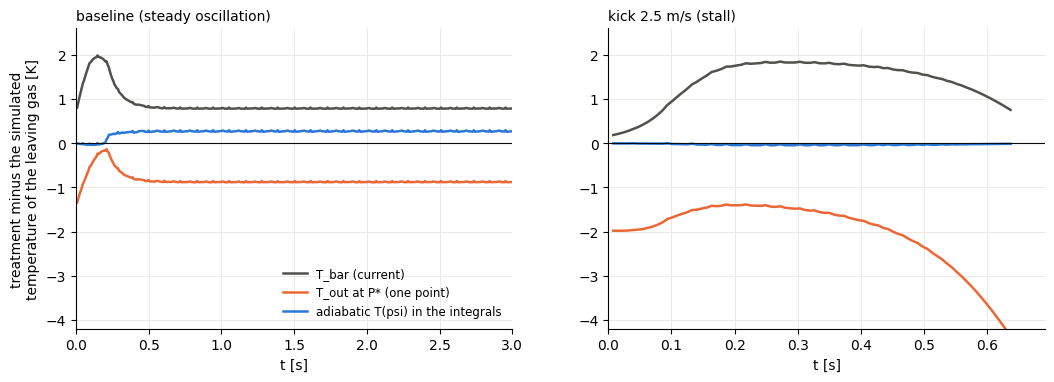

baseline (steady oscillation)  mean |error| over the live cycles:  T_bar 0.88 K,  T_out 0.84 K,  adiabatic T(psi) 0.25 K   (largest: 1.99 / 1.35 / 0.30 K)
kick 2.5 m/s (stall)           mean |error| over the live cycles:  T_bar 1.39 K,  T_out 2.03 K,  adiabatic T(psi) 0.03 K   (largest: 1.85 / 4.36 / 0.05 K)


In [2]:
diag = {}
for kw, title in [(dict(), 'baseline (steady oscillation)'), (dict(v0=2.5), 'kick 2.5 m/s (stall)')]:
    mm = Model(**kw); tt, PP, TT = mm.run_full(t_end_for(mm))
    tm_, Pm_, half_, Tm_, Tflow_ = per_cycle(mm, tt, PP, TT)
    ex = np.array([mm.outlet(Pm_[i], Tm_[i], half_[i], 'exact') for i in range(len(tm_))])
    with np.errstate(invalid='ignore', divide='ignore'):
        T_exact_ = np.where(np.abs(ex[:, 0]) > 1e-7, ex[:, 1] / ex[:, 0], np.nan)
    diag[title] = dict(tm=tm_, half=half_, err={'Tbar': Tm_ - Tflow_, 'Tout': Tm_ * (mm.Pstar / Pm_) ** mm.eps - Tflow_, 'exact': T_exact_ - Tflow_},
                       Tflow=Tflow_)

fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.9)); fig.subplots_adjust(wspace=0.22)
for ax, (title, dg) in zip(axs, diag.items()):
    live = dg['half'] > 0.05 * dg['half'].max()
    for mode in MODES:
        ax.plot(dg['tm'][live], dg['err'][mode][live], '-', color=MODE_COL[mode], lw=1.8, label=MODE_LAB[mode])
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_xlim(0, dg['tm'][live].max()); ax.set_ylim(-4.2, 2.6)
    ax.set_xlabel('t [s]'); ax.set_title(title, fontsize=10, loc='left')
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
axs[0].set_ylabel('treatment minus the simulated\ntemperature of the leaving gas [K]')
axs[0].legend(frameon=False, fontsize=8.5, loc='lower right')
plt.show()
for title, dg in diag.items():
    live = dg['half'] > 0.05 * dg['half'].max()
    print('%-30s mean |error| over the live cycles:  T_bar %.2f K,  T_out %.2f K,  adiabatic T(psi) %.2f K   (largest: %.2f / %.2f / %.2f K)'
          % (title, *[np.nanmean(np.abs(dg['err'][mo][live])) for mo in MODES], *[np.nanmax(np.abs(dg['err'][mo][live])) for mo in MODES]))

## 2. The 37 sweep settings: envelope and mean pressure

For each setting the full simulation is run once and reduced to per-cycle mean pressure, half swing and mean temperature; the averaged model is then integrated three times, once per treatment, and observed at the same cycle times. Error measures (averaged model minus simulation):

- **mean pressure**: the signed median over the plateau (cycles above half the maximum swing) and the largest absolute error over the whole run, in mbar;
- **envelope**: the median relative error over the plateau, and the rms error over the whole run as a percentage of the largest swing (this one also sees the growth and the collapse);
- **outcome**: steady oscillation or stall at the end of the run, against the simulation;
- **mean temperature**: the signed median error of $\bar T$ over the plateau, in K (not a pressure measure, shown because it is where the treatments differ most).

In [3]:
rows, traces = [], {}
tic = time.time()
for key, (label, vals) in SWEEPS.items():
    for v in vals:
        model = Model(**{key: v}); te = t_end_for(model)
        t, P, T = model.run_full(te)
        tm, Pm, half, Tm, Tflow = per_cycle(model, t, P, T)
        plateau = half > 0.5 * half.max()
        late = tm > te - 0.1
        sus_sim = bool(late.any() and half[late].mean() > 1e3)
        traces[(key, v)] = dict(tm=tm, Pm=Pm, half=half, Tm=Tm, Tflow=Tflow)
        line = '%-8s = %-8g sim %-6s |' % (key, v, 'steady' if sus_sim else 'stall')
        for mode in MODES:
            sol = model.run_avg(te, mode)
            Mb, Pb, a = sol.sol(tm)
            Vc = np.array([model.geom(p)[1] for p in Pb]); kcv = np.array([model.geom(p)[2] for p in Pb])
            d = kcv * np.maximum(a, 0) / model.A_neck; Tb = Pb * Vc / (Mb * model.R)
            Mend, Pend, aend = sol.sol(te - 1e-3)
            d_end = model.geom(Pend)[2] * max(aend, 0) / model.A_neck
            r = dict(sweep=key, value=v, mode=mode, sim=('steady' if sus_sim else 'stall'), avg=('steady' if d_end > 1e3 else 'stall'),
                     mean_err_plateau=float(np.median((Pb - Pm)[plateau]) / 100), mean_err_max=float(np.max(np.abs(Pb - Pm)) / 100),
                     env_err_plateau=float(100 * np.median(np.abs(d - half)[plateau] / half[plateau])),
                     env_err_run=float(100 * np.sqrt(np.mean((d - half) ** 2)) / half.max()),
                     T_err_plateau=float(np.median((Tb - Tm)[plateau])))
            rows.append(r); traces[(key, v)][mode] = dict(Pb=Pb, d=d, Tb=Tb)
            line += '  %s: dP %+5.1f mbar, env %4.2f%%/%4.2f%%, %s' % (mode, r['mean_err_plateau'], r['env_err_plateau'], r['env_err_run'], r['avg'][:6])
        print(line + '   [%3.0f s]' % (time.time() - tic))
df = pd.DataFrame(rows)

m_max    = 0.00025  sim stall  |  Tbar: dP  -5.5 mbar, env 2.82%/5.27%, stall  Tout: dP  -3.2 mbar, env 1.77%/2.78%, stall  exact: dP  -4.3 mbar, env 2.11%/3.91%, stall   [  9 s]


m_max    = 0.0005   sim steady |  Tbar: dP  +7.5 mbar, env 0.03%/0.80%, steady  Tout: dP  +7.6 mbar, env 0.03%/0.58%, steady  exact: dP  +7.6 mbar, env 0.05%/0.61%, steady   [ 30 s]


m_max    = 0.001    sim steady |  Tbar: dP  +8.0 mbar, env 0.04%/0.28%, steady  Tout: dP  +8.2 mbar, env 0.02%/0.21%, steady  exact: dP  +8.1 mbar, env 0.02%/0.21%, steady   [ 44 s]


m_max    = 0.002    sim steady |  Tbar: dP  +8.4 mbar, env 0.05%/0.19%, steady  Tout: dP  +8.6 mbar, env 0.03%/0.15%, steady  exact: dP  +8.5 mbar, env 0.04%/0.15%, steady   [ 53 s]


m_max    = 0.004    sim steady |  Tbar: dP  +8.7 mbar, env 0.02%/0.18%, steady  Tout: dP  +8.8 mbar, env 0.02%/0.17%, steady  exact: dP  +8.7 mbar, env 0.02%/0.17%, steady   [ 60 s]


...

P_in     = 585000   sim stall  |  Tbar: dP  -1.3 mbar, env 1.83%/0.93%, stall  Tout: dP  -0.8 mbar, env 1.27%/0.54%, stall  exact: dP  -1.1 mbar, env 1.54%/0.75%, stall   [378 s]


P_in     = 590000   sim stall  |  Tbar: dP  -2.3 mbar, env 3.05%/4.15%, stall  Tout: dP  -0.6 mbar, env 1.69%/1.56%, stall  exact: dP  -1.3 mbar, env 2.25%/2.66%, stall   [381 s]


P_in     = 600000   sim steady |  Tbar: dP  +8.0 mbar, env 0.04%/0.28%, steady  Tout: dP  +8.2 mbar, env 0.02%/0.21%, steady  exact: dP  +8.1 mbar, env 0.02%/0.21%, steady   [395 s]


P_in     = 620000   sim stall  |  Tbar: dP  -3.1 mbar, env 3.07%/2.85%, stall  Tout: dP  -2.5 mbar, env 2.80%/2.64%, stall  exact: dP  -4.1 mbar, env 3.73%/3.77%, stall   [399 s]


P_in     = 650000   sim stall  |  Tbar: dP  -1.2 mbar, env 3.20%/1.89%, stall  Tout: dP  -1.6 mbar, env 3.29%/2.11%, stall  exact: dP  -1.5 mbar, env 3.89%/2.28%, stall   [402 s]


In [4]:
# summary over the 37 settings, one row per treatment
summ = []
for mode in MODES:
    d = df[df['mode'] == mode]
    summ.append(dict(treatment=MODE_LAB[mode],
                     **{'mean err, plateau, median |.| [mbar]': d.mean_err_plateau.abs().median(),
                        'mean err, plateau, worst |.| [mbar]': d.mean_err_plateau.abs().max(),
                        'mean err, whole run, worst [mbar]': d.mean_err_max.max(),
                        'envelope err, plateau, median [%]': d.env_err_plateau.median(),
                        'envelope err, whole run rms, median [%]': d.env_err_run.median(),
                        'envelope err, whole run rms, worst [%]': d.env_err_run.max(),
                        'outcome agrees with simulation': '%d of %d' % ((d.avg == d.sim).sum(), len(d)),
                        'mean T err, plateau, median [K]': d.T_err_plateau.median()}))
summary = pd.DataFrame(summ).set_index('treatment').T
pd.set_option('display.width', 220); pd.set_option('display.max_rows', 200)

# how much do the alternatives move the prediction relative to the current one?
piv = {q: df.pivot_table(index=['sweep', 'value'], columns='mode', values=q, sort=False) for q in ['mean_err_plateau', 'env_err_run', 'T_err_plateau']}
for q, unit in [('mean_err_plateau', 'mbar'), ('env_err_run', '% of max swing'), ('T_err_plateau', 'K')]:
    p = piv[q]
    print('%-17s  change vs T_bar:  T_out median %+.2f, largest %+.2f %s;   adiabatic T(psi) median %+.2f, largest %+.2f %s'
          % (q, (p.Tout - p.Tbar).median(), (p.Tout - p.Tbar).abs().max() * np.sign((p.Tout - p.Tbar)[(p.Tout - p.Tbar).abs().idxmax()]), unit,
             (p.exact - p.Tbar).median(), (p.exact - p.Tbar).abs().max() * np.sign((p.exact - p.Tbar)[(p.exact - p.Tbar).abs().idxmax()]), unit))
changed = df.pivot_table(index=['sweep', 'value'], columns='mode', values='avg', aggfunc='first', sort=False)
diff = changed[(changed.Tout != changed.Tbar) | (changed.exact != changed.Tbar)]
print('settings where a treatment changes the steady/stall verdict of the averaged model: %s' % (', '.join('%s = %g' % k for k in diff.index) if len(diff) else 'none'))
summary.round(2)

mean_err_plateau   change vs T_bar:  T_out median +0.21, largest +10.08 mbar;   adiabatic T(psi) median +0.11, largest +4.72 mbar
env_err_run        change vs T_bar:  T_out median -0.07, largest -92.10 % of max swing;   adiabatic T(psi) median -0.07, largest -71.71 % of max swing
T_err_plateau      change vs T_bar:  T_out median +0.46, largest +0.82 K;   adiabatic T(psi) median +0.20, largest +0.49 K
settings where a treatment changes the steady/stall verdict of the averaged model: v0 = 2.5


treatment,T_bar (current),T_out at P* (one point),adiabatic T(psi) in the integrals
"mean err, plateau, median |.| [mbar]",7.988531,7.9717,8.023995
"mean err, plateau, worst |.| [mbar]",13.269929,9.50848,9.411056
"mean err, whole run, worst [mbar]",273.667654,39.020072,120.499417
"envelope err, plateau, median [%]",0.042518,0.030916,0.031051
"envelope err, whole run rms, median [%]",0.374194,0.30166,0.317757
"envelope err, whole run rms, worst [%]",100.564936,8.462535,28.859357
outcome agrees with simulation,36 of 37,37 of 37,37 of 37
"mean T err, plateau, median [K]",-0.907415,-0.431295,-0.703689


## 3. Outcome and the e-fold budget

The budget of section 9 is recomputed with each treatment: the slow equations are integrated with no oscillation ($\delta = 0$) and the treatment's outlet temperature, and $\lambda_{lin}$ is integrated up to its first zero. At $\delta = 0$ the adiabatic treatment differs from $\bar T$ only through the in-phase temperature swing riding on the mean outflow (the term $\gamma R\bar{\dot m}_{out}T'/\bar V$ that section 5.1 put in brackets), while $T_{out}$ lowers the outflow temperature by $(P^*/\bar P)^{\varepsilon}$ even though there is no swing yet. The need, $\ln(\delta_{steady}/\delta_0)$, is the same for all three (the median steady amplitude of the simulations), so only $B$ changes.

In [5]:
d_steady = float(np.median([traces[(r.sweep, r.value)]['half'][-1] for r in df[(df['mode'] == 'Tbar') & (df.sim == 'steady')].itertuples()]))
brows = []
for key, (label, vals) in SWEEPS.items():
    for v in vals:
        model = Model(**{key: v}); need = float(np.log(d_steady / model.delta0()))
        sim = df[(df.sweep == key) & (df.value == v)].sim.iloc[0]
        row = dict(sweep=key, value='%g' % v, sim=sim, need=need)
        for mode in MODES:
            B, t1, nowin = model.fill_budget(mode)
            row['B_' + mode] = B; row['verdict_' + mode] = 'steady' if (not nowin and B > need) else 'stall'
        brows.append(row)
bud = pd.DataFrame(brows)
for mode in MODES:
    ok = (bud['verdict_' + mode] == bud.sim)
    print('budget with %-34s right in %d of %d;  misses: %s' % (MODE_LAB[mode], ok.sum(), len(bud), ', '.join('%s = %s' % (r.sweep, r.value) for r in bud[~ok].itertuples())))
print('steady amplitude used for the need: %.0f mbar' % (d_steady / 100))
print('B change vs T_bar:  T_out median %+.3f (range %+.3f to %+.3f);  adiabatic T(psi) median %+.3f (range %+.3f to %+.3f) e-folds'
      % ((bud.B_Tout - bud.B_Tbar).median(), (bud.B_Tout - bud.B_Tbar).min(), (bud.B_Tout - bud.B_Tbar).max(),
         (bud.B_exact - bud.B_Tbar).median(), (bud.B_exact - bud.B_Tbar).min(), (bud.B_exact - bud.B_Tbar).max()))
tab = bud[['sweep', 'value', 'sim', 'need', 'B_Tbar', 'B_Tout', 'B_exact', 'verdict_Tbar', 'verdict_Tout', 'verdict_exact']].copy()
tab.columns = ['sweep', 'value', 'simulation', 'need', 'B (T_bar)', 'B (T_out)', 'B (adiabatic)', 'verdict T_bar', 'verdict T_out', 'verdict adiabatic']
tab.round(3)

budget with T_bar (current)                    right in 35 of 37;  misses: zeta = 1.2, P_in = 620000
budget with T_out at P* (one point)            right in 35 of 37;  misses: zeta = 1.2, P_in = 620000
budget with adiabatic T(psi) in the integrals  right in 35 of 37;  misses: zeta = 1.2, P_in = 620000
steady amplitude used for the need: 295 mbar
B change vs T_bar:  T_out median -0.036 (range -0.138 to +0.002);  adiabatic T(psi) median -0.008 (range -0.032 to +0.000) e-folds


,sweep,value,simulation,need,B (T_bar),B (T_out),B (adiabatic),verdict T_bar,verdict T_out,verdict adiabatic
0,m_max,0.00025,stall,0.739,0.334,0.317,0.326,stall,stall,stall
1,m_max,0.0005,steady,0.739,1.051,1.020,1.042,steady,steady,steady
2,m_max,0.001,steady,0.739,1.423,1.387,1.414,steady,steady,steady
3,m_max,0.002,steady,0.739,1.609,1.570,1.600,steady,steady,steady
4,m_max,0.004,steady,0.739,1.702,1.662,1.693,steady,steady,steady
5,zeta,0.4,stall,0.739,0.034,0.030,0.011,stall,stall,stall
6,zeta,0.5,steady,0.739,1.060,1.015,1.039,steady,steady,steady
7,zeta,0.6,steady,0.739,1.423,1.387,1.414,steady,steady,steady
8,zeta,0.8,steady,0.739,1.003,0.993,1.002,steady,steady,steady
9,zeta,1,steady,0.739,1.179,1.179,1.179,steady,steady,steady


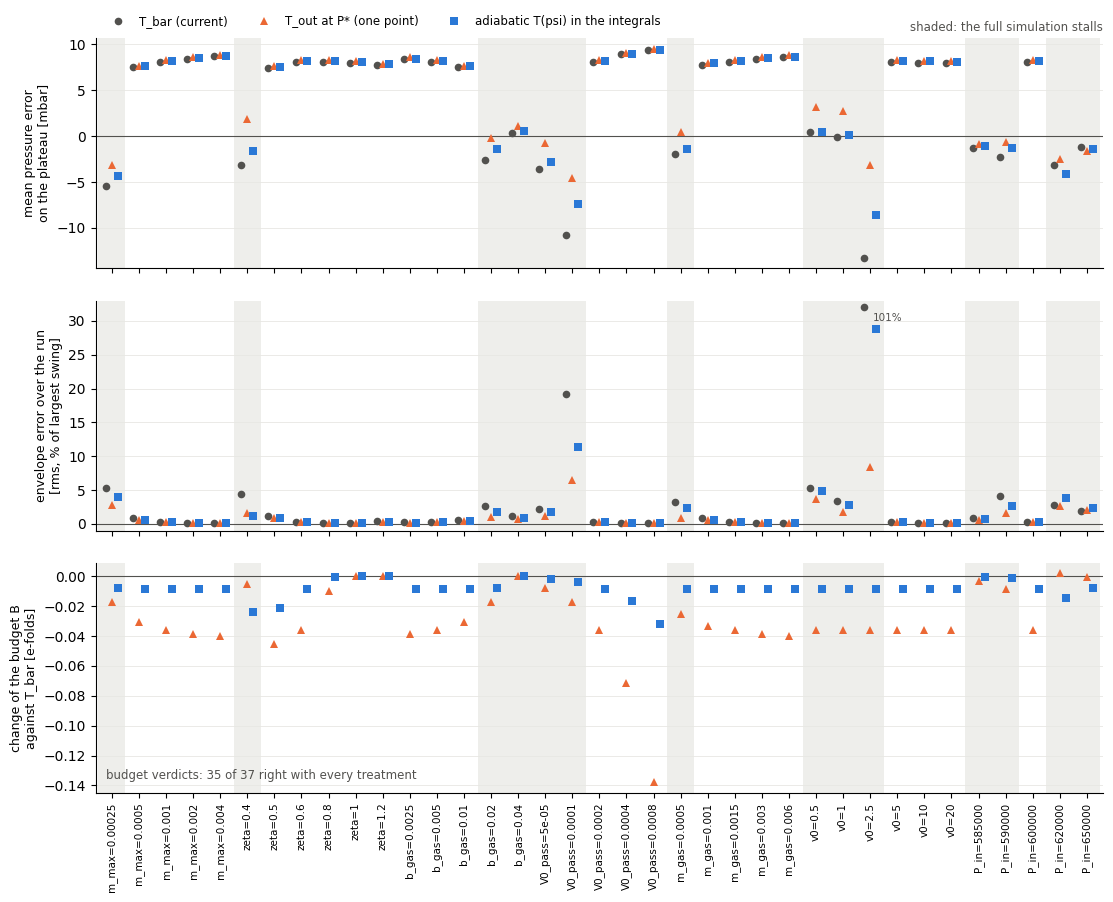

In [6]:
names = ['%s=%g' % k for k in piv['mean_err_plateau'].index]
x = np.arange(len(names)); marks = {'Tbar': 'o', 'Tout': '^', 'exact': 's'}; off = {'Tbar': -0.22, 'Tout': 0.0, 'exact': 0.22}
fig, axs = plt.subplots(3, 1, figsize=(13, 9.8), sharex=True); fig.subplots_adjust(hspace=0.14)
stalled = np.array([df[(df['mode'] == 'Tbar') & (df.sweep == k[0]) & (df.value == k[1])].sim.iloc[0] == 'stall' for k in piv['mean_err_plateau'].index])
dB = {mode: (bud['B_' + mode] - bud.B_Tbar).values for mode in MODES}
panels = [(lambda mo: piv['mean_err_plateau'][mo].values, MODES, 'mean pressure error\non the plateau [mbar]', None),
          (lambda mo: piv['env_err_run'][mo].values, MODES, 'envelope error over the run\n[rms, % of largest swing]', (0, 32)),
          (lambda mo: dB[mo], ('Tout', 'exact'), 'change of the budget B\nagainst T_bar [e-folds]', None)]
for ax, (getter, modes, ylab, ylim) in zip(axs, panels):
    for i in np.where(stalled)[0]:
        ax.axvspan(i - 0.5, i + 0.5, color=GRID, alpha=0.7, lw=0, zorder=0)
    for mode in modes:
        y = getter(mode)
        yp = np.clip(y, *ylim) if ylim else y
        ax.plot(x + off[mode], yp, marks[mode], color=MODE_COL[mode], ms=5.5, mew=0, label=MODE_LAB[mode], zorder=3)
        if ylim is not None:
            for i in np.where(y > ylim[1])[0]:
                ax.annotate('%.0f%%' % y[i], (x[i] + off[mode], ylim[1]), xytext=(6, -10), textcoords='offset points', fontsize=7.5, color=INK2)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_ylabel(ylab, fontsize=9)
    if ylim: ax.set_ylim(ylim[0] - 1, ylim[1] + 1)
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
axs[0].legend(frameon=False, fontsize=8.5, ncol=3, loc='lower left', bbox_to_anchor=(0.0, 1.0))
axs[0].text(1.0, 1.02, 'shaded: the full simulation stalls', transform=axs[0].transAxes, ha='right', va='bottom', fontsize=8.5, color=INK2)
axs[2].text(0.01, 0.06, 'budget verdicts: 35 of 37 right with every treatment', transform=axs[2].transAxes, fontsize=8.5, color=INK2)
axs[2].set_xticks(x); axs[2].set_xticklabels(names, rotation=90, fontsize=7.5)
axs[2].set_xlim(-0.6, len(names) - 0.4)
plt.show()

## 4. The smallest kick that survives

A single number that summarizes how well each treatment follows the race between growth and filling: the kick threshold of the baseline, found by bisection on $v_0$ — once with the full simulation, once per treatment with the averaged model.

In [7]:
def steady_full(v0, t_end=3.0):
    mm = Model(v0=v0); tt, PP, TT = mm.run_full(t_end)
    tm_, Pm_, half_, Tm_, Tf_ = per_cycle(mm, tt, PP, TT)
    late = tm_ > t_end - 0.1
    return bool(late.any() and half_[late].mean() > 1e3)


def steady_avg(v0, mode, t_end=3.0):
    mm = Model(v0=v0); sol = mm.run_avg(t_end, mode); Mb, Pb, a = sol.sol(t_end - 1e-3)
    return mm.geom(Pb)[2] * max(a, 0.0) / mm.A_neck > 1e3


def bisect(is_steady, lo, hi, tol):
    while hi - lo > tol:
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if is_steady(mid) else (mid, hi)
    return lo, hi


tic = time.time()
thr = {'full simulation': bisect(steady_full, 2.3, 2.9, 0.01)}
for mode in MODES:
    thr[MODE_LAB[mode]] = bisect(lambda v: steady_avg(v, mode), 1.5, 4.0, 0.002)
for k, (lo, hi) in thr.items():
    print('%-36s kick threshold %.3f - %.3f m/s' % (k, lo, hi))
full_mid = 0.5 * sum(thr['full simulation'])
for mode in MODES:
    mid = 0.5 * sum(thr[MODE_LAB[mode]])
    print('%-36s closes %3.0f%% of the gap between T_bar and the full simulation' % (MODE_LAB[mode], 100 * (mid - 0.5 * sum(thr[MODE_LAB['Tbar']])) / (full_mid - 0.5 * sum(thr[MODE_LAB['Tbar']]))))
print('[%.0f s]' % (time.time() - tic))

full simulation                      kick threshold 2.619 - 2.628 m/s
T_bar (current)                      kick threshold 2.475 - 2.477 m/s
T_out at P* (one point)              kick threshold 2.574 - 2.575 m/s
adiabatic T(psi) in the integrals    kick threshold 2.525 - 2.527 m/s
T_bar (current)                      closes   0% of the gap between T_bar and the full simulation
T_out at P* (one point)              closes  67% of the gap between T_bar and the full simulation
adiabatic T(psi) in the integrals    closes  34% of the gap between T_bar and the full simulation
[90 s]


## 5. What this says

**What changes in the derivation.** Three places, all on the outlet side; the structure does not change.

- *The valve gain (17).* The outlet term $\bar T N_{out}$ becomes $T_{out}N_{out}$ (one point) or $H_{1,out}/\delta$ (adiabatic). For a small swing the adiabatic version is $\bar T\left(N_{out} + \varepsilon\dot m_{0,out}/\bar P\right)$: the extra piece is the bracketed term $\gamma R\bar{\dot m}_{out}T'/\bar V$ of section 5.1, which lowers $g$ by $\gamma\varepsilon\dot m_{0,out}/\bar M$, about 0.16 per second in the baseline.
- *The mean-pressure equation (26).* The flux $T_{in}\dot m_{0,in} - \bar T\dot m_{0,out}$ becomes $T_{in}\dot m_{0,in} - T_{out}\dot m_{0,out}$ or $T_{in}\dot m_{0,in} - H_{0,out}$. For a small swing $H_{0,out} = \bar T\left(\dot m_{0,out} + \varepsilon N_{out}\delta^2/2\bar P\right)$: a $\delta^2$ term of the same kind as the acoustic-power term.
- *Section 9.* The clean identity $g_{lin} = (c^2/\bar V_{cv}) d\dot m_{net}/d\bar P$ needs the same temperature on both valves. With the adiabatic treatment nothing changes at $\delta = 0$ except the small term above. With $T_{out}$ the net inflow is replaced by $\dot m_{in} - \theta\dot m_{out}$, $\theta = T_{out}/T_{in} \approx 0.993$: the balance pressure moves down by about 1 mbar and $B$ drops by about 0.04 e-folds.

The mass equation (23), the frequency (12) and the envelope law (20)–(22) are unchanged.

**Which treatment approximates the pressure better.** For steady oscillations none of them is better: the steady mean pressure is set by the mass balance, and the steady amplitude changes by less than 0.1 percent; the remaining +8 mbar mean offset is not a temperature effect. For the growth and the stall the treatment does matter, and both alternatives beat $\bar T$. The adiabatic $T(\psi)$ is the one that is right for the right reason: it uses only the adiabatic cycle of section 4, and it gets the temperature of the leaving gas to within 0.05 K. The one-point $T_{out}$ is better still on the pressure of the stall runs and on the kick threshold, but it overcools the outflow there by 1.4 to 4.4 K, and the extra cooling raises the mean pressure by more than the true temperature effect — offsetting a lag of the averaged model's mean during the filling that remains even with the adiabatic treatment and comes from its other approximations. If the derivation is changed, the adiabatic version is the one to adopt; $T_{out}$ is a convenient proxy with that caveat.